<a href="https://colab.research.google.com/github/rejithust/ustassignment1/blob/main/diabetes_prediction_ust1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Prediction using Machine Learning

**Goal:** build a machine learning app that predicts whether a patient has diabetes based on medical fields.

Dataset: `diabetes.csv` (768 patients, 8 medical features, binary target `Outcome`).

## Part 1 — Data Preparation

### 1.1 Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 1.2 Explore the dataset

In [3]:
print("Shape of the dataset:", df.shape)

Shape of the dataset: (768, 9)


In [4]:
print("Columns:", list(df.columns))

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [5]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [6]:
print("Missing values (as stored in the raw file):")
print(df.isnull().sum())

Missing values (as stored in the raw file):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


### 1.3 Feature and target description

| Column | Description | Type | Units / notes |
|---|---|---|---|
| `Pregnancies` | Number of times pregnant | Integer | Count. Zero is valid. |
| `Glucose` | Plasma glucose concentration (2-hour oral glucose tolerance test) | Numeric | mg/dL. Zero is physiologically impossible. |
| `BloodPressure` | Diastolic blood pressure | Numeric | mm Hg. Zero is invalid. |
| `SkinThickness` | Triceps skin fold thickness | Numeric | mm. Zero is invalid. |
| `Insulin` | 2-hour serum insulin | Numeric | µU/mL. Zero is invalid. |
| `BMI` | Body mass index | Numeric | kg/m². Zero is invalid. |
| `DiabetesPedigreeFunction` | Diabetes pedigree function (family history score) | Numeric | Unitless. Zero is valid. |
| `Age` | Age of the patient | Integer | Years |
| **`Outcome`** (target) | Diabetes diagnosis | Binary | 0 = No diabetes, 1 = Diabetes |

### 1.4 Invalid zeros

In five columns a value of 0 cannot be a real measurement, so it is recorded as a missing value. Zeros in `Pregnancies` and `DiabetesPedigreeFunction` are valid and kept.

In [8]:
zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df[zero_as_missing_cols] == 0).sum().rename("zero_count")
zero_counts

,zero_count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


### 1.5 Separate features (X) and target variable (y)

In [9]:
df_clean = df.copy()
df_clean[zero_as_missing_cols] = df_clean[zero_as_missing_cols].replace(0, np.nan)

print("Missing values after converting invalid zeros to NaN:")
print(df_clean.isnull().sum())

Missing values after converting invalid zeros to NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [10]:
X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

print("Features (X) shape:", X.shape)
print("Target (y) class proportions:")
print(y.value_counts(normalize=True).rename("proportion").round(3))

Features (X) shape: (768, 8)
Target (y) class proportions:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


### 1.6 Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape, y_train.shape)
print("Testing set size: ", X_test.shape, y_test.shape)
print("Diabetic proportion, train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Training set size: (614, 8) (614,)
Testing set size:  (154, 8) (154,)
Diabetic proportion, train: 0.349 | test: 0.351


`stratify=y` keeps the same ~65/35 class ratio in both splits, so the test set represents the full dataset.

### 1.7 Preprocessing: impute missing values and scale features

- **Missing values:** median imputation on all five invalid-zero columns. The medians are learned from the training set only, so no information leaks from the test set.
- **Scaling:** standard scaling, because the features have very different ranges.
- **Encoding:** not required, since all features are numeric.

In [12]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Imputation medians (learned from training data):")
print(pd.Series(imputer.statistics_, index=X.columns, name="median").round(2))
print()
print("Preprocessing complete. Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)

Imputation medians (learned from training data):
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00
Name: median, dtype: float64

Preprocessing complete. Train: (614, 8) | Test: (154, 8)


### 1.8 Feature engineering check

Several features are strongly right-skewed. A `log(1 + x)` transform compresses long tails, which can help linear models. The baseline model in Part 2 keeps the raw features so it matches the original submission. The transform is tested as a candidate in Part 4.

In [13]:
skew = X.skew().rename("skewness").round(2).sort_values(ascending=False)
skew

,skewness
Insulin,2.17
DiabetesPedigreeFunction,1.92
Age,1.13
Pregnancies,0.90
SkinThickness,0.69
BMI,0.59
Glucose,0.53
BloodPressure,0.13


In [14]:
LOG_COLS = ["Insulin", "DiabetesPedigreeFunction"]

def log_transform(frame):
    out = frame.copy()
    out[LOG_COLS] = np.log1p(out[LOG_COLS])
    return out

print("Columns log-transformed in the candidate model:", LOG_COLS)

Columns log-transformed in the candidate model: ['Insulin', 'DiabetesPedigreeFunction']


**Part 1 summary**
- Dataset: 768 rows × 9 columns (8 features + `Outcome`). No nulls in the raw file.
- Five biologically invalid zeros treated as missing: `Glucose` (5), `BloodPressure` (35), `SkinThickness` (227), `Insulin` (374), `BMI` (11). Zeros in `Pregnancies` and `DiabetesPedigreeFunction` are valid and kept.
- Features (X): 8 numeric columns. Target (y): `Outcome`, imbalanced (about 65% no diabetes, 35% diabetes).
- Split: 80/20, stratified. 614 training rows, 154 test rows.
- Preprocessing: median imputation on all five columns, then standard scaling, both fit on training data only. No encoding needed.
- Feature engineering: `Insulin` and `DiabetesPedigreeFunction` are strongly skewed. A log transform is evaluated in Part 4.

## Part 2 — Machine Learning Model Building

**Algorithm choice: Logistic Regression.**

This is a binary classification problem, and Logistic Regression is a suitable baseline for it:

- It models the probability of the positive class. The output is a risk score a clinician can act on, not just a 0/1 label.
- Its coefficients are interpretable. On standardized features they show each variable's direction and relative strength.
- With 8 features and 614 training rows it has limited capacity, so it is less prone to overfitting than flexible models. Part 3 shows a moderate train/test gap, so overfitting is limited, not absent.
- It can handle class imbalance directly through `class_weight`, which Part 4 tests.
- Its main limitation is that it is linear. Random Forest is tested in Part 4 as a non-linear alternative.

In [15]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
model

LogisticRegression(max_iter=1000, random_state=42)

In [16]:
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False).reset_index(drop=True)

coef_table.round(3)

,Feature,Coefficient
0,Glucose,1.183
1,BMI,0.689
2,Pregnancies,0.377
3,DiabetesPedigreeFunction,0.233
4,Age,0.148
5,Insulin,-0.066
6,BloodPressure,-0.044
7,SkinThickness,0.028


Coefficients are computed on standardized features, so their sizes are directly comparable. A positive value means a higher feature value is associated with higher odds of diabetes.

- `Glucose` (1.18) is the largest, about 1.7 times `BMI` (0.69).
- `Pregnancies` (0.38), `DiabetesPedigreeFunction` (0.23) and `Age` (0.15) are smaller positive contributors.
- `Insulin`, `BloodPressure` and `SkinThickness` have near-zero or negative coefficients. Their values are heavily imputed (see Part 4), so these estimates should be read with caution.

## Part 3 — Model Training & Evaluation

### 3.1 Training accuracy

In [17]:
y_train_pred = model.predict(X_train_scaled)
train_accuracy = accuracy_score(y_train, y_train_pred)

print(f"Training accuracy: {train_accuracy:.4f}")

Training accuracy: 0.7964


### 3.2 Test-set evaluation

In [18]:
y_test_pred = model.predict(X_test_scaled)

test_accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print(f"Test accuracy:        {test_accuracy:.4f}")
print(f"Precision (diabetes): {precision:.4f}")
print(f"Recall (diabetes):    {recall:.4f}")
print(f"F1-score (diabetes):  {f1:.4f}")
print()
print(classification_report(y_test, y_test_pred, target_names=["No Diabetes", "Diabetes"]))

Test accuracy:        0.7078
Precision (diabetes): 0.6000
Recall (diabetes):    0.5000
F1-score (diabetes):  0.5455

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



### 3.3 Confusion matrix

Confusion matrix (rows = actual, columns = predicted):
[[82 18]
 [27 27]]
True negatives: 82 | False positives: 18 | False negatives: 27 | True positives: 27


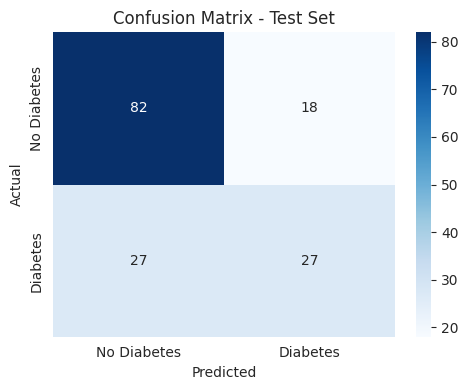

In [19]:
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()

### 3.4 Training vs. testing performance

In [20]:
train_recall_pos = recall_score(y_train, y_train_pred, pos_label=1)
test_recall_pos = recall_score(y_test, y_test_pred, pos_label=1)
train_recall_neg = recall_score(y_train, y_train_pred, pos_label=0)
test_recall_neg = recall_score(y_test, y_test_pred, pos_label=0)

summary = pd.DataFrame({
    "Accuracy": [train_accuracy, test_accuracy],
    "Recall (diabetes)": [train_recall_pos, test_recall_pos],
    "Recall (no diabetes)": [train_recall_neg, test_recall_neg],
}, index=["Train", "Test"])
summary.loc["Gap (train - test)"] = summary.loc["Train"] - summary.loc["Test"]
summary.round(3)

,Accuracy,Recall (diabetes),Recall (no diabetes)
Train,0.796,0.593,0.905
Test,0.708,0.500,0.820
Gap (train - test),0.089,0.093,0.085


**Interpretation**

- **Overall fit.** Train accuracy is 0.796 and test accuracy is 0.708, a gap of 0.089. This is moderate. The model fits seen data better than unseen data, but a simple linear model limits how much it can overfit.
- **Accuracy is flattered by class imbalance.** Predicting "no diabetes" for everyone would score 0.649 on the test set, so the model is only about 6 points better than that trivial baseline.
- **The main weakness is recall on the diabetic class.** The model catches 27 of 54 diabetic patients in the test set (recall 0.50). Recall for non-diabetic patients is 0.82. Half of diabetic patients are missed, which is the costly error for a screening tool.
- **Precision for the diabetic class is 0.60:** 27 of the 45 patients flagged as diabetic truly have it.

## Part 4 — Model Performance Analysis

### 4.1 Exploratory views

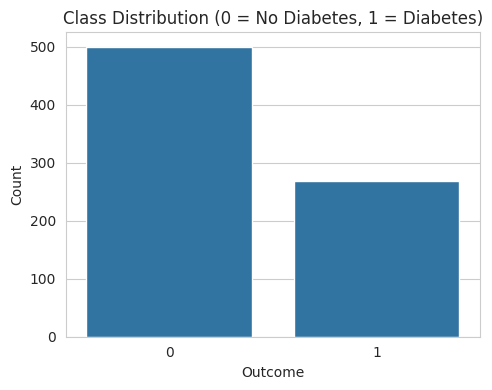

In [21]:
plt.figure(figsize=(5, 4))
sns.countplot(x="Outcome", data=df_clean)
plt.title("Class Distribution (0 = No Diabetes, 1 = Diabetes)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.tight_layout()

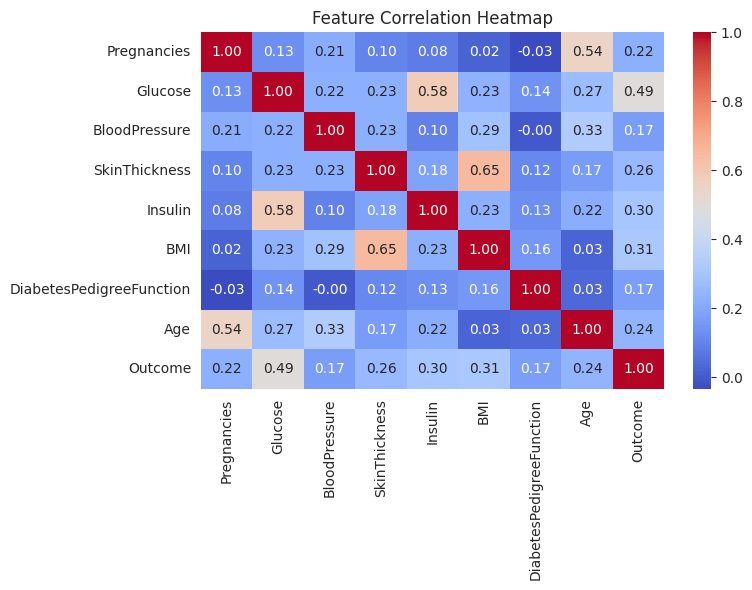

In [22]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()

### 4.2 Comparing candidate models

Every candidate uses the same train/test split. Imputation and scaling sit inside a pipeline, so they are re-fit within each cross-validation fold and nothing leaks from validation folds into training. "CV recall" is 5-fold stratified cross-validation on the training set only, so the test set is used once for the final numbers.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = [
    ("LR baseline (Part 2 model)", LogisticRegression(max_iter=1000, random_state=42), False),
    ("LR, class_weight='balanced'", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42), False),
    ("LR, balanced + log features", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42), True),
    ("Random Forest, balanced", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42), False),
]

rows = []
for name, estimator, use_log in candidates:
    X_tr_c = log_transform(X_train) if use_log else X_train
    X_te_c = log_transform(X_test) if use_log else X_test

    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), estimator)
    cv_recall = cross_val_score(pipe, X_tr_c, y_train, cv=cv, scoring="recall").mean()

    pipe.fit(X_tr_c, y_train)
    y_hat = pipe.predict(X_te_c)
    _, _, _, tp_c = confusion_matrix(y_test, y_hat).ravel()

    rows.append({
        "Model": name,
        "CV recall (train)": cv_recall,
        "Test accuracy": accuracy_score(y_test, y_hat),
        "Test precision": precision_score(y_test, y_hat),
        "Test recall": recall_score(y_test, y_hat),
        "Test F1": f1_score(y_test, y_hat),
        "Diabetic patients caught (of 54)": tp_c,
    })

comparison_df = pd.DataFrame(rows).set_index("Model")
comparison_df.round(3)

,CV recall (train),Test accuracy,Test precision,Test recall,Test F1,Diabetic patients caught (of 54)
Model,,,,,,
LR baseline (Part 2 model),0.575,0.708,0.600,0.500,0.545,27
"LR, class_weight='balanced'",0.701,0.734,0.603,0.704,0.650,38
"LR, balanced + log features",0.715,0.734,0.600,0.722,0.655,39
"Random Forest, balanced",0.593,0.734,0.644,0.537,0.586,29


### 4.3 Threshold sensitivity (baseline model)

The default decision threshold is 0.5. Lowering it flags more patients as diabetic, which raises recall and lowers precision.

These values are computed on the test set for illustration only. For a deployed tool the threshold should be chosen with cross-validation on the training data, so the test set stays untouched.

In [23]:
baseline_pipe = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
baseline_pipe.fit(X_train, y_train)
proba = baseline_pipe.predict_proba(X_test)[:, 1]

rows = []
for t in [0.5, 0.4, 0.3]:
    y_hat = (proba >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, y_hat),
        "Precision": precision_score(y_test, y_hat),
        "Recall": recall_score(y_test, y_hat),
        "F1": f1_score(y_test, y_hat),
    })

pd.DataFrame(rows).set_index("Threshold").round(3)

,Accuracy,Precision,Recall,F1
Threshold,,,,
0.5,0.708,0.600,0.500,0.545
0.4,0.734,0.614,0.648,0.631
0.3,0.740,0.597,0.796,0.683


### 4.4 Findings

1. **Class weighting substantially improves recall without hurting precision.** Balanced logistic regression raises test recall from 0.50 to 0.70, catching 38 of 54 diabetic patients instead of 27. Precision stays at about 0.60. The cost is 7 more false positives (18 → 25). Cross-validated recall on the training data points the same way (0.58 → 0.70), so the gain is not an artifact of one test split.
2. **The log transform adds little.** Test recall moves from 0.70 to 0.72, one patient, and CV recall from 0.70 to 0.72. On a 154-row test set this is within noise, so the feature engineering step does not materially change the model.
3. **Random Forest does not improve recall.** It has the highest test precision of the group, but its recall is lower (0.54 on test, 0.59 in CV). For a screening tool, that trade-off is the wrong way round.
4. **Lowering the threshold is the same trade-off.** Moving the threshold from 0.5 to 0.4 or 0.3 raises test recall to 0.65 and 0.80 while precision falls. Choose the threshold with cross-validation, not on the test set.

**Recommendation.** For screening, use logistic regression with `class_weight="balanced"` as the production candidate. It keeps the interpretability of the Part 2 model and substantially reduces missed diagnoses. Pick the final threshold with cross-validation, then validate once on held-out data.

**Feature drivers.** `Glucose` is the strongest predictor, followed by `BMI` and `Pregnancies`. Glucose is itself a diagnostic test, so the model largely reproduces a known criterion. The tool's added value is most relevant where glucose has not been measured.

### 4.5 Limitations

- **Small sample.** There are 768 patients, and only 54 diabetic patients in the test set. One patient changes test recall by about 1.9 percentage points, so differences of one or two patients are not meaningful.
- **Heavy imputation.** `Insulin` is missing for 49% of patients (374 of 768) and `SkinThickness` for 30% (227). Their coefficients are weakly identified, so conclusions about them are tentative.
- **Single population.** The data covers Pima Indian women. Results should not be assumed to hold for other populations or clinical settings without external validation.
- **Limited validation.** Results come from one 80/20 split plus 5-fold cross-validation on the training set. Repeated cross-validation or an external dataset would give a more reliable estimate.